<a href="https://colab.research.google.com/github/nur21horin/Deep_Learning_Learning/blob/main/Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
X = np.array([
 [4.0, 9.0, -0.2, 0.2], # Genuine-like
 [3.5, 8.5, -0.4, 0.1], # Genuine-like
 [0.1, 1.0, 5.0, -4.0], # Counterfeit-like
 [-0.5, 0.5, 6.0, -3.5], # Counterfeit-like
 [3.9, 8.8, -0.3, 0.3], # Genuine-like
 [0.2, 1.2, 4.8, -3.8], # Counterfeit-like
 [3.6, 8.4, -0.5, 0.0], # Genuine-like
 [-0.3, 0.7, 5.5, -3.7] # Counterfeit-like
])

In [ ]:
Y=np.array([1,1,0,0,1,0,1,0])


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [ ]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [ ]:
model=Sequential()

In [ ]:
model.add(Dense(units=8,activation='relu',input_shape=(X_train.shape[1],)))
model.add(Dense(units=1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49 (196.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
history=model.fit(X_train,y_train,epochs=10,batch_size=4,verbose=0)


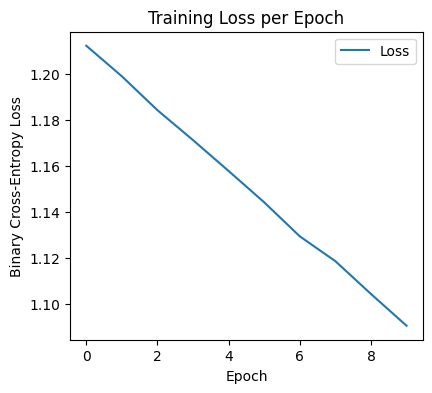

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.title('Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()

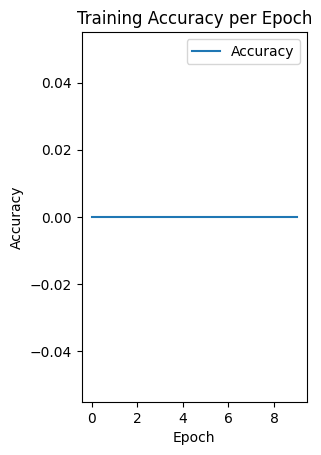

In [ ]:
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy')
plt.title('Training Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [ ]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nANN Test Accuracy (Simulated Counterfeit Detection):\n{accuracy*100:.2f}%")


ANN Test Accuracy (Simulated Counterfeit Detection):
0.00%
